<a href="https://colab.research.google.com/github/Safwanach2002/ML/blob/main/Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Mount Google Drive
drive.mount('/content/drive')

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/DatasetLR.csv')

print("Dataset Loaded Successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset Loaded Successfully!


In [ ]:
# 1. LOAD AND INSPECT DATASET

# a) First 10 records
print(df.head(10))

# b) Number of rows and columns
print(df.shape)

# c) Column names
print(df.columns.tolist())

# d) Missing values
print(df.isnull().sum())

# e) Duplicate records
print(df.duplicated().sum())

# f) Dependent and independent variables
print("Dependent Variable: Exam_Score")
print("Independent Variables: Study_Hours, Sleep_Hours, Attendance, Previous_Score, Assignments_Completed")

   Study_Hours  Sleep_Hours  Attendance  Previous_Score  \
0          1.5          5.7          93              88   
1          6.5          6.6          72              69   
2          4.1          7.9          92              50   
3          6.1          6.8          98              90   
4          7.8          7.3          88              52   
5          4.8          7.7          79              66   
6          4.5          8.0          90              72   
7          1.5          7.8          91              86   
8          2.9          5.5          90              83   
9          4.5          6.8          74              74   

   Assignments_Completed  Exam_Score  
0                     92        60.9  
1                     79        82.1  
2                     74        71.4  
3                     75        84.9  
4                     99        89.0  
5                     64        72.0  
6                     96        72.4  
7                     94        61.4  

                       Study_Hours  Sleep_Hours  Attendance  Previous_Score  \
Study_Hours               1.000000     0.155749    0.080967       -0.147930   
Sleep_Hours               0.155749     1.000000   -0.142734       -0.080044   
Attendance                0.080967    -0.142734    1.000000       -0.110322   
Previous_Score           -0.147930    -0.080044   -0.110322        1.000000   
Assignments_Completed    -0.037457     0.143731   -0.025918        0.003584   
Exam_Score                0.958313     0.264658    0.115301        0.025894   

                       Assignments_Completed  Exam_Score  
Study_Hours                        -0.037457    0.958313  
Sleep_Hours                         0.143731    0.264658  
Attendance                         -0.025918    0.115301  
Previous_Score                      0.003584    0.025894  
Assignments_Completed               1.000000    0.074850  
Exam_Score                          0.074850    1.000000  
Strongest Feature: Study_Hours


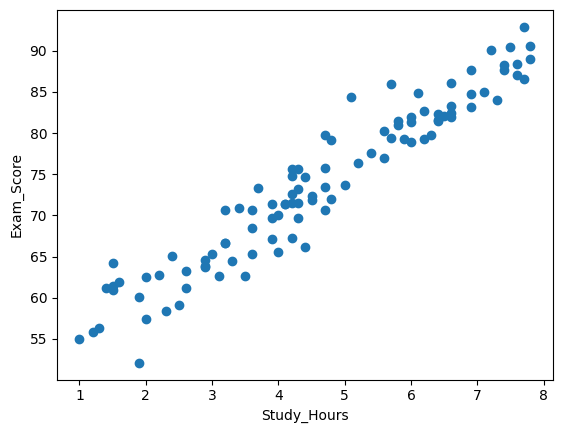

In [ ]:
# 2. CORRELATION ANALYSIS

# a) Correlation matrix
corr = df.corr(numeric_only=True)
print(corr)

# b) Strongest correlated feature
strongest = corr["Exam_Score"].drop("Exam_Score").abs().idxmax()
print("Strongest Feature:", strongest)

# c) Scatter plot
plt.scatter(df[strongest], df["Exam_Score"])
plt.xlabel(strongest)
plt.ylabel("Exam_Score")
plt.show()

In [ ]:
# 3. MULTIPLE LINEAR REGRESSION

# a) Select independent and dependent variables
X = df[["Study_Hours", "Sleep_Hours", "Attendance",
        "Previous_Score", "Assignments_Completed"]]
y = df["Exam_Score"]

# b) Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# c) Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict Exam_Score
y_pred = model.predict(X_test)

print("Model Trained Successfully!")
print("Predicted Scores:", y_pred[:5])

Model Trained Successfully!
Predicted Scores: [82.21559186 74.20902374 81.51800398 82.4096506  70.84471606]


In [ ]:
# 4. REGRESSION EQUATION

# a) Display intercept
print("Intercept:", model.intercept_)

# b) Display coefficients
print("Coefficients:", model.coef_)

# c) Display regression equation
print("\nRegression Equation:")

print("Exam_Score =", model.intercept_)

for name, coef in zip(X.columns, model.coef_):
    print("+", round(coef, 2), "*", name)

Intercept: 16.174179199719937
Coefficients: [5.07014087 1.37900534 0.0823862  0.15161055 0.08536743]

Regression Equation:
Exam_Score = 16.174179199719937
+ 5.07 * Study_Hours
+ 1.38 * Sleep_Hours
+ 0.08 * Attendance
+ 0.15 * Previous_Score
+ 0.09 * Assignments_Completed


In [ ]:
# 5. MODEL EVALUATION

# a) Calculate MAE
mae = mean_absolute_error(y_test, y_pred)

# b) Calculate MSE
mse = mean_squared_error(y_test, y_pred)

# c) Calculate RMSE
rmse = np.sqrt(mse)

# d) Calculate R2
r2 = r2_score(y_test, y_pred)

# e) Calculate Adjusted R2
n = len(y_test)
p = X_test.shape[1]
adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

# Display results
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)
print("Adjusted R2:", adj_r2)

MAE: 0.8310910050914654
MSE: 1.0113326354943053
RMSE: 1.0056503544941977
R2: 0.9883776611272511
Adjusted R2: 0.9842268258155551


In [ ]:
# 6. EFFECT OF ADDING PREDICTORS

# Define three models
features1 = ["Study_Hours"]
features2 = ["Study_Hours", "Sleep_Hours"]
features3 = ["Study_Hours", "Sleep_Hours", "Attendance",
             "Previous_Score", "Assignments_Completed"]

results = []

# Train and evaluate each model
for features in [features1, features2, features3]:

    m = LinearRegression()
    m.fit(X_train[features], y_train)

    pred = m.predict(X_test[features])

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    n = len(y_test)
    p = len(features)
    adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

    results.append([mae, mse, rmse, r2, adj_r2])

# Display comparison table
table = pd.DataFrame(results,
    columns=["MAE", "MSE", "RMSE", "R2", "Adjusted R2"],
    index=["Model 1", "Model 2", "Model 3"])

print(table)

# Best model
print("\nBest Model:", table["R2"].idxmax())

              MAE       MSE      RMSE        R2  Adjusted R2
Model 1  1.956783  5.231123  2.287165  0.939883     0.936544
Model 2  2.010808  5.627060  2.372142  0.935333     0.927725
Model 3  0.831091  1.011333  1.005650  0.988378     0.984227

Best Model: Model 3


In [ ]:
# 7. GRADIENT DESCENT

# a) Standardize input features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Standardize target variable
y_mean = y_train.mean()
y_std = y_train.std()
y_train_scaled = (y_train - y_mean) / y_std

# b) Implement Gradient Descent
def gradient_descent(X, y, lr=0.01, epochs=2000):
    n, p = X.shape
    w = np.zeros(p)
    b = 0

    for i in range(epochs):
        pred = X @ w + b
        error = pred - y

        w = w - lr * (2/n) * (X.T @ error)
        b = b - lr * (2/n) * np.sum(error)

    return w, b

# Train model
weights, bias = gradient_descent(X_train_scaled, y_train_scaled)

# c) Display weights and bias
print("Final Weights:", weights)
print("Final Bias:", bias)

# d) Predict exam score
gd_pred = (X_test_scaled @ weights + bias) * y_std + y_mean

# e) Model evaluation
mae = mean_absolute_error(y_test, gd_pred)
mse = mean_squared_error(y_test, gd_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, gd_pred)

n = len(y_test)
p = X_test.shape[1]
adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

print("\nMAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)
print("Adjusted R2:", adj_r2)

Final Weights: [0.9439263  0.12692493 0.07622456 0.17408572 0.09685655]
Final Bias: 1.4988427166073877e-15

MAE: 0.8310910050903744
MSE: 1.0113326354928662
RMSE: 1.005650354493482
R2: 0.9883776611272677
Adjusted R2: 0.9842268258155775


Learning Rate: 0.001
Final Cost: 0.0252428451668458
Learning Rate: 0.01
Final Cost: 0.024500139309197554
Learning Rate: 0.1
Final Cost: 0.02450013930919755


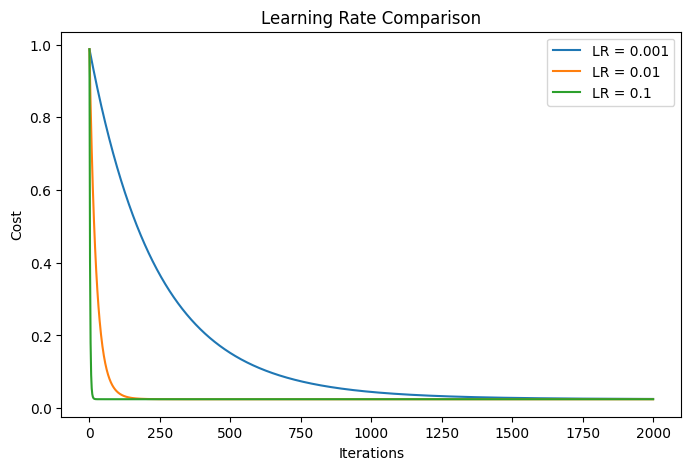

In [ ]:
# 8. LEARNING RATE EXPERIMENT

# Different learning rates
rates = [0.001, 0.01, 0.1]

# Gradient Descent function with cost
def gradient_descent(X, y, lr, epochs=2000):
    n, p = X.shape
    w = np.zeros(p)
    b = 0
    cost = []

    for i in range(epochs):
        pred = X @ w + b
        error = pred - y

        w -= lr * (2/n) * (X.T @ error)
        b -= lr * (2/n) * np.sum(error)

        cost.append(np.mean(error**2))

    return w, b, cost

# Train and plot cost curves
plt.figure(figsize=(8, 5))

for lr in rates:
    w, b, cost = gradient_descent(
        X_train_scaled, y_train_scaled, lr
    )

    print("Learning Rate:", lr)
    print("Final Cost:", cost[-1])

    plt.plot(cost, label=f"LR = {lr}")

# Display cost curves
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Learning Rate Comparison")
plt.legend()
plt.show()

In [ ]:
# 9. SCIKIT-LEARN VS GRADIENT DESCENT

# Scikit-learn prediction
sk_pred = model.predict(X_test)

# Function to calculate evaluation metrics
def evaluate(actual, predicted, p):
    n = len(actual)

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

    return [mae, mse, rmse, r2, adj_r2]

# Compare both models
comparison = pd.DataFrame(
    [evaluate(y_test, sk_pred, 5),
     evaluate(y_test, gd_pred, 5)],

    columns=["MAE", "MSE", "RMSE", "R2", "Adjusted R2"],
    index=["Scikit-learn", "Gradient Descent"]
)

print(comparison)

                       MAE       MSE     RMSE        R2  Adjusted R2
Scikit-learn      0.831091  1.011333  1.00565  0.988378     0.984227
Gradient Descent  0.831091  1.011333  1.00565  0.988378     0.984227


In [ ]:
# 10. PREDICTION FOR A NEW STUDENT

# Create a new student
new_student = pd.DataFrame({
    "Study_Hours": [5],
    "Sleep_Hours": [8],
    "Attendance": [90],
    "Previous_Score": [75],
    "Assignments_Completed": [8]
})

# Predict Exam Score
prediction = model.predict(new_student)

# Display result
print("Predicted Exam Score:", prediction[0])

Predicted Exam Score: 72.02541457323412


In [ ]:
# LINEAR REGRESSION ASSIGNMENT

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Mount Google Drive and Load Dataset
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/DatasetLR.csv')


# 1. LOAD AND INSPECT DATASET

# a) First 10 records
print("\n1. First 10 Records:")
print(df.head(10))

# b) Rows and columns
print("\nShape:", df.shape)

# c) Column names
print("\nColumns:", df.columns.tolist())

# d) Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# e) Duplicate records
print("\nDuplicates:", df.duplicated().sum())

# f) Dependent and independent variables
print("\nDependent Variable: Exam_Score")
print("Independent Variables: Study_Hours, Sleep_Hours, Attendance, Previous_Score, Assignments_Completed")


# 2. CORRELATION ANALYSIS

# a) Correlation matrix
corr = df.corr(numeric_only=True)
print("\n2. Correlation Matrix:")
print(corr)

# b) Strongest correlated feature
strongest = corr["Exam_Score"].drop("Exam_Score").abs().idxmax()
print("\nStrongest Feature:", strongest)

# c) Scatter plot
plt.scatter(df[strongest], df["Exam_Score"])
plt.xlabel(strongest)
plt.ylabel("Exam_Score")
plt.title("Scatter Plot")
plt.show()


# 3. MULTIPLE LINEAR REGRESSION

X = df[["Study_Hours", "Sleep_Hours", "Attendance",
        "Previous_Score", "Assignments_Completed"]]
y = df["Exam_Score"]

# 80% Training and 20% Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\n3. Model Trained Successfully!")


# 4. REGRESSION EQUATION

print("\n4. Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

equation = f"Exam_Score = {model.intercept_:.3f}"
for name, coef in zip(X.columns, model.coef_):
    equation += f" + ({coef:.3f} * {name})"

print("Regression Equation:", equation)


# 5. MODEL EVALUATION

def evaluate(actual, predicted, p):
    n = len(actual)
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    adj_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))
    return [mae, mse, rmse, r2, adj_r2]

print("\n5. Model Evaluation:")
print("MAE, MSE, RMSE, R2, Adjusted R2")
print(evaluate(y_test, y_pred, 5))


# 6. EFFECT OF ADDING PREDICTORS

features = [
    ["Study_Hours"],
    ["Study_Hours", "Sleep_Hours"],
    ["Study_Hours", "Sleep_Hours", "Attendance",
     "Previous_Score", "Assignments_Completed"]
]

results = []

for f in features:
    m = LinearRegression()
    m.fit(X_train[f], y_train)
    pred = m.predict(X_test[f])
    results.append(evaluate(y_test, pred, len(f)))

table = pd.DataFrame(
    results,
    columns=["MAE", "MSE", "RMSE", "R2", "Adjusted R2"],
    index=["Model 1", "Model 2", "Model 3"]
)

print("\n6. Model Comparison:")
print(table)
print("Best Model:", table["R2"].idxmax())


# 7. GRADIENT DESCENT

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Standardize target
y_mean = y_train.mean()
y_std = y_train.std()
y_train_scaled = (y_train.to_numpy() - y_mean) / y_std

# Gradient Descent function
def gradient_descent(X, y, lr=0.01, epochs=2000):
    n, p = X.shape
    w = np.zeros(p)
    b = 0
    costs = []

    for i in range(epochs):
        pred = X @ w + b
        error = pred - y
        w -= lr * (2/n) * (X.T @ error)
        b -= lr * (2/n) * np.sum(error)
        costs.append(np.mean(error**2))

    return w, b, costs

# Train model
weights, bias, costs = gradient_descent(
    X_train_scaled, y_train_scaled)

gd_pred = (X_test_scaled @ weights + bias) * y_std + y_mean

print("\n7. Gradient Descent Weights:", weights)
print("Bias:", bias)
print("Evaluation:", evaluate(y_test, gd_pred, 5))


# 8. LEARNING RATE EXPERIMENT

rates = [0.001, 0.01, 0.1]

plt.figure(figsize=(8, 5))

for lr in rates:
    w, b, cost = gradient_descent(
        X_train_scaled, y_train_scaled, lr)

    pred = (X_test_scaled @ w + b) * y_std + y_mean

    print("\nLearning Rate:", lr)
    print("Evaluation:", evaluate(y_test, pred, 5))

    plt.plot(cost, label=f"LR={lr}")

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Learning Rate Comparison")
plt.legend()
plt.show()


# 9. SCIKIT-LEARN VS GRADIENT DESCENT

comparison = pd.DataFrame(
    [evaluate(y_test, y_pred, 5),
     evaluate(y_test, gd_pred, 5)],
    columns=["MAE", "MSE", "RMSE", "R2", "Adjusted R2"],
    index=["Scikit-learn", "Gradient Descent"]
)

print("\n9. Model Comparison:")
print(comparison)


# 10. PREDICTION FOR A NEW STUDENT

new_student = pd.DataFrame({
    "Study_Hours": [5],
    "Sleep_Hours": [8],
    "Attendance": [90],
    "Previous_Score": [75],
    "Assignments_Completed": [8]
})

prediction = model.predict(new_student)

print("\n10. New Student Predicted Exam Score:")
print(prediction[0])